In [1]:
import os
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt

In [2]:
pth = os.path.join('..', '..', '..', '..')
pth_data = os.path.join(pth, 'data')
pth_in = os.path.join(pth_data, 'cancer', 'invertebrate', 'holigactis')
pth_out = os.path.join(pth_data, 'results', 'cancer', 'holigactis')
pth_fig = os.path.join(pth, 'figures', 'cancer', 'invertebrate', 'holigactis')
pth_cb = os.path.join(pth_fig, 'colorbars')

In [3]:
adata = sc.read_h5ad(os.path.join(pth_in, 'tumor.h5ad'))
adata.obs['sample'] = adata.obs_names.astype('category')
adata

AnnData object with n_obs × n_vars = 4 × 9971
    obs: 'sample'
    layers: 'gProcessedSignal'

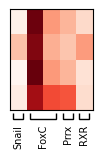

In [ ]:
# source: H. vulgaris NCBI names + blast
g_plt = {
    'Snail' : ['HOLI00251.G8870'],
    'FoxC'  : ['HOLI11838.G1764', 'HOLI00925.G36738'],
    'Prrx'  : ['HOLI07521.G24635'],
    'RXR'   : ['HOLI00661.G36072'],
    ''}

# expression heatmap
fs = 7
hm = sc.pl.heatmap(adata, g_plt, 'sample',
                   cmap = 'Reds',
                   figsize = (1.5, 1.5),
                   show_gene_labels = False,
                   show = False)

ax_hm = hm['heatmap_ax']
ax_grp = hm['groupby_ax']
ax_var = hm['gene_groups_ax']
ax_cb = ax_hm.figure.axes[1]
ax_cb.set_visible(False)
ax_grp.set_visible(False)

for ax in (ax_hm, ax_var):
    ax.invert_yaxis()

for t in ax_var.texts:
    t.set_va('top')
    t.set_fontsize(fs)

for l in ax_var.patches:
    l.set_linewidth(1)

for l in ax_hm.collections:
    l.remove()

pos_hm  = ax_hm.get_position()
pos_var = ax_var.get_position()
ax_var.set_position([pos_var.x0,
                     pos_hm.y0 - pos_var.height - .02,
                     pos_var.width,
                     pos_var.height])

# fn = os.path.join(pth_fig, 'expression.pdf')
# plt.savefig(fn, bbox_inches = 'tight', dpi = 1200)
plt.show()

/tmp/ipykernel_2990580/2780792314.py:3: UserWarning: Adding colorbar to a different Figure <Figure size 150x150 with 4 Axes> than <Figure size 66x100 with 1 Axes> which fig.colorbar is called on.
  cb = plt.colorbar(ax_cb.collections[1], cax = cax)


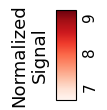

In [6]:
fig = plt.figure(figsize = (.66, 1))
cax = fig.add_axes([.35, .05, .3, .905])
cb = plt.colorbar(ax_cb.collections[1], cax = cax)
cb.ax.tick_params(which = 'both', size = 0)
cb.set_label('Normalized\nSignal', size = 13, labelpad = 5)
cb.ax.yaxis.set_label_position('left')
cb.ax.tick_params('y', rotation = 90, labelsize = 11, pad = 5)
fn = os.path.join(pth_cb, 'expression.pdf')
plt.savefig(fn, bbox_inches = 'tight')

In [6]:
# save results
df = pd.concat({
      name : pd.DataFrame(adata[:, g].X, columns = [g],
                          index = adata.obs_names)
      for name, g in g_plt.items()}, axis = 1).T
df.to_csv(os.path.join(pth_out, 'expression.csv'))